## Wstęp do Uczenia Maszynowego

#### Laboratorium 05


### Zakres laboratorium

- reprodukowalność podziałów danych i eksperymentów
- przygotowanie danych: wartości odstające i braki danych
- `Pipeline` i `ColumnTransformer`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


In [2]:
df = pd.read_csv("titanic.csv")
df

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest,survived
0,1.0,"Allen, Miss. Elisabeth Walton",female,29.0000,0.0,0.0,24160,211.3375,B5,S,2,NaN,"St Louis, MO",1
1,1.0,"Allison, Master. Hudson Trevor",male,0.9167,1.0,2.0,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON",1
2,1.0,"Allison, Miss. Helen Loraine",female,2.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
3,1.0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON",0
4,1.0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1.0,2.0,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,3.0,"Zabour, Miss. Hileni",female,14.5000,1.0,0.0,2665,14.4542,NaN,C,NaN,328.0,NaN,0
1305,3.0,"Zabour, Miss. Thamine",female,NaN,1.0,0.0,2665,14.4542,NaN,C,NaN,NaN,NaN,0
1306,3.0,"Zakarian, Mr. Mapriededer",male,26.5000,0.0,0.0,2656,7.2250,NaN,C,NaN,304.0,NaN,0
1307,3.0,"Zakarian, Mr. Ortin",male,27.0000,0.0,0.0,2670,7.2250,NaN,C,NaN,NaN,NaN,0


| Nazwa kolumny | Opis                                            |
|---------------|-------------------------------------------------|
| pclass        | Klasa biletu                                    |
| name          | Imię i nazwisko pasażera                        |
| sex           | Płeć pasażera                                   |
| age           | Wiek pasażera w latach                          |
| sibsp         | Liczba rodzeństwa / współmałżonków na pokładzie |
| parch         | Liczba rodziców / dzieci na pokładzie           |
| ticket        | Numer biletu                                    |
| fare          | Cena biletu (w funtach szterlingach z 1912 r.)  |
| cabin         | Numer kabiny                                    |
| embarked      | Port, w którym pasażer wsiadł na pokład         |
| boat          | Numer łodzi ratunkowej (dla ocalałych)          |
| body          | Numer odnalezionego ciała (dla zmarłych)        |
| home.dest     | Dom / Miejsce docelowe pasażera                 |
| survived      | Status przeżycia                                |

In [3]:
y = df.survived
X = df.drop(["survived"], axis = 1)

### 1. Przygotowanie danych

#### Wartości odstające

Wartość skrajna nie musi być błędem. Najpierw wykrywamy takie obserwacje i sprawdzamy ich znaczenie w kontekście problemu; usuwamy je lub przekształcamy dopiero wtedy, gdy mamy ku temu uzasadnienie.


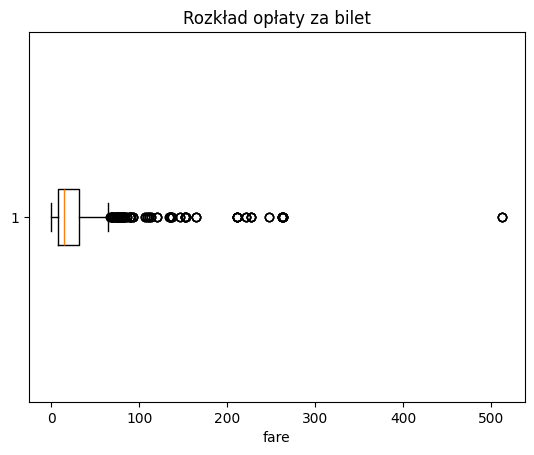

Próg 1,5 IQR: 66.34


,pclass,fare,name
183,1.0,512.3292,"Lesurer, Mr. Gustave J"
302,1.0,512.3292,"Ward, Miss. Anna"
49,1.0,512.3292,"Cardeza, Mr. Thomas Drake Martinez"
50,1.0,512.3292,"Cardeza, Mrs. James Warburton Martinez (Charlo..."
111,1.0,263.0000,"Fortune, Miss. Alice Elizabeth"


In [4]:
# Rozkład opłaty za bilet. Boxplot wskazuje obserwacje daleko od pozostałych,
# ale sam nie rozstrzyga, czy są one błędami.
fig, ax = plt.subplots()
ax.boxplot(df["fare"].dropna(), orientation="horizontal")
ax.set_xlabel("fare")
ax.set_title("Rozkład opłaty za bilet")
plt.show()

q1, q3 = df["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
fare_extreme = df.loc[df["fare"] > upper_fence, ["pclass", "fare", "name"]]
print(f"Próg 1,5 IQR: {upper_fence:.2f}")
fare_extreme.sort_values("fare", ascending=False).head()


W tym zbiorze wysokie wartości `fare` odpowiadają drogim biletom, więc nie traktujemy ich automatycznie jako błędów i ich nie usuwamy. Gdyby celem było modelowanie wrażliwe na silnie skośny rozkład, można byłoby później rozważyć np. transformację `log1p(fare)` $\Big(ln(1+x)\Big)$.

#### Braki danych

Braki można uzupełniać różnie zależnie od typu zmiennej, np. średnią dla cech numerycznych albo najczęstszą kategorią dla cech kategorycznych. Ważne, aby parametry imputacji wyznaczać tylko na danych treningowych — `Pipeline` zapewnia to automatycznie.


-----
##### *Zadanie 1*

Przyjrzyj się danym `titanic`. Korzystając z informacji o typach, brakach i rozkładach, podziel kolumny na: przydatne bez zmian, wymagające przygotowania oraz takie, które należy usunąć.


In [5]:
# Podstawowe informacje o typach kolumn i brakach danych.
X.info()
print("\nLiczba braków w kolumnach:")
print(X.isna().sum().sort_values(ascending=False))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   float64
 1   name       1309 non-null   object 
 2   sex        1309 non-null   object 
 3   age        1046 non-null   float64
 4   sibsp      1309 non-null   float64
 5   parch      1309 non-null   float64
 6   ticket     1309 non-null   object 
 7   fare       1308 non-null   float64
 8   cabin      295 non-null    object 
 9   embarked   1307 non-null   object 
 10  boat       486 non-null    object 
 11  body       121 non-null    float64
 12  home.dest  745 non-null    object 
dtypes: float64(6), object(7)
memory usage: 133.1+ KB

Liczba braków w kolumnach:
body         1188
cabin        1014
boat          823
home.dest     564
age           263
embarked        2
fare            1
pclass          0
name            0
sex             0
sibsp           0
parch        

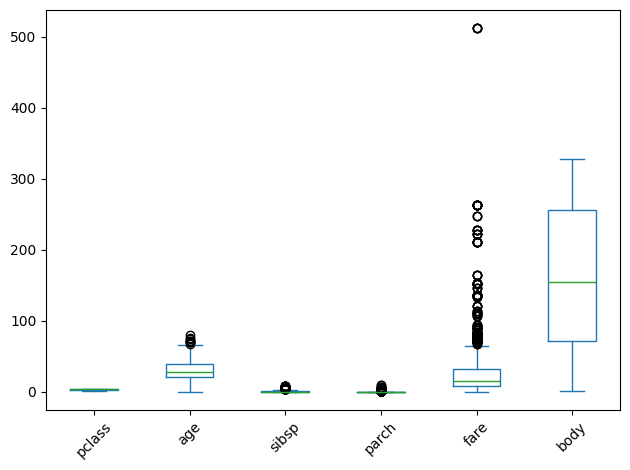

In [6]:
# Rozkłady cech numerycznych pomagają zauważyć braki i wartości skrajne.
X.select_dtypes(include="number").plot.box(rot=45)
plt.tight_layout()
plt.show()


#### Decyzje dotyczące kolumn

- `age` i `fare` zawierają braki, więc wymagają imputacji.
- `sex` i `embarked` są cechami kategorycznymi; `embarked` także ma braki.
- `name`, `ticket` i `home.dest` mają dużą liczbę różnych wartości, a `cabin` jest prawie w całości pusty.
- `boat` i `body` opisują informacje dostępne po katastrofie, więc powodowałyby **przeciek danych** (*target leakage*).

Zachowujemy `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`.


In [8]:
columns_to_drop = ["name", "ticket", "cabin", "boat", "body", "home.dest", "embarked"]
X = X.drop(columns=columns_to_drop)


-----
##### *Zadanie 2*

Przygotuj listy `numerical_features` i `categorical_features`, zawierające odpowiednio nazwy kolumn numerycznych i kategorycznych. Uruchom kod i sprawdź, czy odpowiadają decyzjom z poprzedniego zadania.


In [9]:
numerical_features = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical_features = ['sex']


-----
##### *Zadanie 2 z gwiazdką*
Jak wykorzystując informację o typach kolumn podzielić je na numeryczne i kategoryczne?


In [10]:
numerical_features = list(X.select_dtypes(include=["number"]).columns)
categorical_features = list(X.select_dtypes(exclude=["number"]).columns)

print("Cechy numeryczne:", numerical_features)
print("Cechy kategoryczne:", categorical_features)

Cechy numeryczne: ['pclass', 'age', 'sibsp', 'parch', 'fare']
Cechy kategoryczne: ['sex']


#### Pipeline dla cech numerycznych

Dla cech numerycznych najpierw uzupełniamy braki średnią, a następnie standaryzujemy wartości. Drzewo nie wymaga skalowania, ale ten sam etap będzie można połączyć później z modelami wrażliwymi na skalę cech.


In [11]:
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])


-----
##### *Zadanie 3*

Przygotuj `Pipeline` dla zmiennych kategorycznych. Użyj `SimpleImputer()` ze strategią wyboru najczęstszej kategorii oraz `OneHotEncoder()` z ignorowaniem nieznanych kategorii.

https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

In [12]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])


#### Połączenie przygotowania danych z modelem

`ColumnTransformer` stosuje właściwy pipeline do każdej grupy kolumn. Następnie cały etap przygotowania łączymy z drzewem w jeden `Pipeline`.

https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html


In [13]:
preprocessor = ColumnTransformer([
    ("numerical", numerical_transformer, numerical_features),
    ("categorical", categorical_transformer, categorical_features),
])

pipeline = Pipeline([
    ("pre", preprocessor),
    ("tree", DecisionTreeClassifier(random_state=42)),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
pipeline.fit(X_train, y_train)

print("Accuracy na zbiorze treningowym:", round(pipeline.score(X_train, y_train), 3))
print("Accuracy na zbiorze testowym:", round(pipeline.score(X_test, y_test), 3))


Accuracy na zbiorze treningowym: 0.97
Accuracy na zbiorze testowym: 0.775


Jeżeli wynik na zbiorze treningowym jest wyraźnie wyższy niż na testowym, może to wskazywać na przeuczenie. W dalszej części laboratorium dostroimy złożoność drzewa za pomocą walidacji krzyżowej.


-----
##### *Zadanie 4*

Wczytaj zbiór danych `pima.csv`. Narysuj rozkład `BloodPressure` osobno dla klas `Outcome` i zastanów się, co mogą oznaczać wartości równe 0.


In [14]:
pima = pd.read_csv("pima.csv")
y = pima["Outcome"]
X = pima.drop(columns="Outcome")


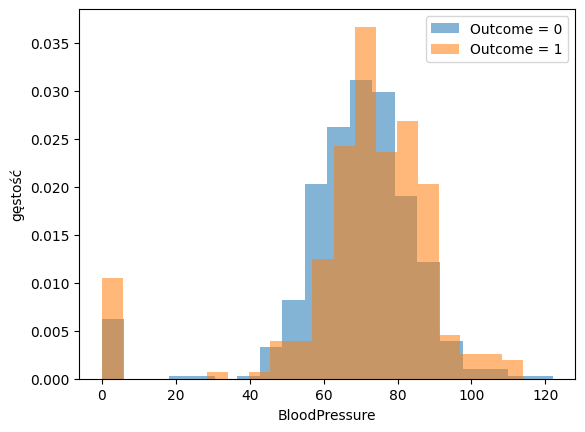

In [15]:
fig, ax = plt.subplots()
for outcome, group in pima.groupby("Outcome"):
    ax.hist(
        group["BloodPressure"], bins=20, density=True, alpha=0.55,
        label=f"Outcome = {outcome}"
    )
ax.set_xlabel("BloodPressure")
ax.set_ylabel("gęstość")
ax.legend()
plt.show()


-----
##### *Zadanie 5*

a) Zastąp wartości 0 zmiennej `BloodPressure` brakami danych. Podziel dane na zbiór treningowy i testowy w proporcji 7:3. Przygotuj `Pipeline` z imputacją średnią i drzewem decyzyjnym. Oblicz `accuracy` na zbiorze treningowym i testowym.

b) Przeprowadź optymalizację hiperparametrów pipeline'u za pomocą `GridSearchCV` z 3-krotną walidacją krzyżową. Rozważ `max_depth` od 5 do 12 oraz `min_samples_leaf` od 3 do 9.

c) Podaj najlepsze parametry i najlepszą wartość accuracy w CV. Na zbiorze testowym porównaj accuracy oraz ROC AUC dostrojonego i bazowego pipeline'u.

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/modules/grid_search.html


In [16]:
# Zera w BloodPressure oznaczają brak pomiaru, a nie rzeczywiste ciśnienie krwi.
X.loc[X["BloodPressure"] == 0, "BloodPressure"] = np.nan


In [17]:
pipeline = Pipeline([
    ("imputation", SimpleImputer(strategy="mean")),
    ("tree", DecisionTreeClassifier(random_state=42)),
])


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
pipeline.fit(X_train, y_train)

print("Accuracy na zbiorze treningowym:", round(pipeline.score(X_train, y_train), 3))
print("Accuracy na zbiorze testowym:", round(pipeline.score(X_test, y_test), 3))


Accuracy na zbiorze treningowym: 1.0
Accuracy na zbiorze testowym: 0.71


In [19]:
# Siatka wartości hiperparametrów, które chcemy porównać.
params = {
    "tree__max_depth": list(range(5, 13)),
    "tree__min_samples_leaf": list(range(3, 10)),
}

# Dzielimy wyłącznie zbiór treningowy na trzy foldy.
# Używamy zwykłego KFold; dla klasyfikatora GridSearchCV domyślnie wybrałby StratifiedKFold.
cv_3 = KFold(n_splits=3, shuffle=True, random_state=42)

# GridSearchCV dopasuje pipeline dla każdej kombinacji parametrów i każdego foldu,
# a następnie wybierze konfigurację o najwyższej średniej accuracy w CV.
grid_pipeline = GridSearchCV(
    estimator=pipeline,
    param_grid=params,
    cv=cv_3,
    scoring="accuracy",
)


In [20]:
grid_pipeline.fit(X_train, y_train)

selected_acc = grid_pipeline.score(X_test, y_test)
baseline_acc = pipeline.score(X_test, y_test)
selected_auc = roc_auc_score(y_test, grid_pipeline.predict_proba(X_test)[:, 1])
baseline_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])

print("Najlepsze parametry:", grid_pipeline.best_params_)
print("Najlepsza accuracy w CV:", round(grid_pipeline.best_score_, 3))
print("Accuracy dostrojonego modelu na teście:", round(selected_acc, 3))
print("ROC AUC dostrojonego modelu na teście:", round(selected_auc, 3))
print("Accuracy bazowego modelu na teście:", round(baseline_acc, 3))
print("ROC AUC bazowego modelu na teście:", round(baseline_auc, 3))


Najlepsze parametry: {'tree__max_depth': 5, 'tree__min_samples_leaf': 4}
Najlepsza accuracy w CV: 0.736
Accuracy dostrojonego modelu na teście: 0.766
ROC AUC dostrojonego modelu na teście: 0.795
Accuracy bazowego modelu na teście: 0.71
ROC AUC bazowego modelu na teście: 0.711


### 2. Reprodukowalność eksperymentów

Losowy podział danych może zmienić nie tylko konkretne obserwacje w zbiorze testowym, ale też rozkład zmiennej docelowej i cech. Ustawienie `random_state` pozwala odtworzyć konkretny eksperyment.


#### Przykład: wpływ losowego podziału danych

Porównajmy kilka podziałów danych `titanic`. Ten sam `random_state` odtwarza identyczny zbiór testowy, ale różne wartości seeda prowadzą do innych obserwacji i nieco innych rozkładów zmiennych.



Ten sam random_state daje identyczny test: True


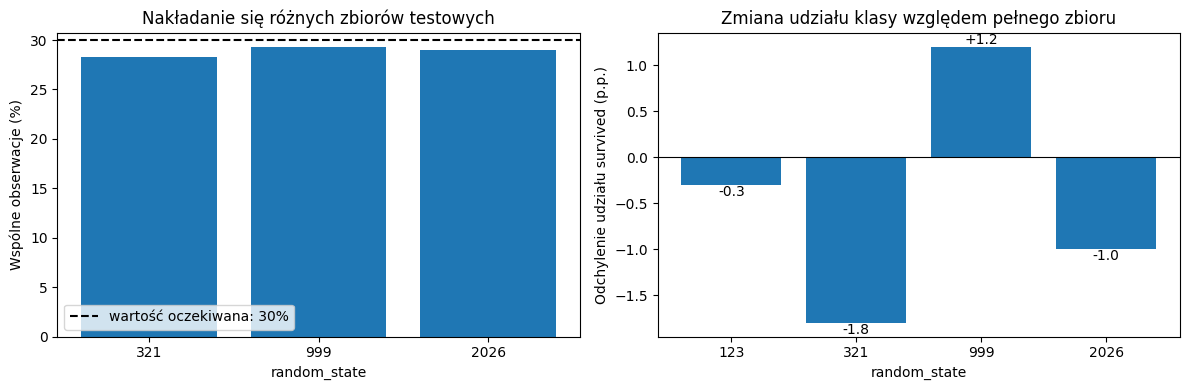

In [21]:
reference_seed = 123
seeds = [123, 321, 999, 2026]
indices = np.arange(len(df))

# Ten sam seed zawsze odtwarza identyczny podział.
_, reference_test_idx = train_test_split(
    indices, test_size=0.3, random_state=reference_seed
)
_, repeated_test_idx = train_test_split(
    indices, test_size=0.3, random_state=reference_seed
)
print("Ten sam random_state daje identyczny test:",
      np.array_equal(reference_test_idx, repeated_test_idx))

rows = []
for seed in seeds:
    _, test_idx = train_test_split(indices, test_size=0.3, random_state=seed)
    test_data = df.iloc[test_idx]
    rows.append({
        "random_state": seed,
        "wspólne obserwacje z seedem 123 (%)": (
            100 * len(np.intersect1d(reference_test_idx, test_idx)) / len(reference_test_idx)
        ),
        "udział osób, które przeżyły": test_data["survived"].mean(),
        "średnia fare": test_data["fare"].mean(),
    })

comparison = pd.DataFrame(rows).round(3)
comparison

# Dla dwóch losowych testów o rozmiarze 30% oczekujemy około 30% wspólnych obserwacji.
comparison_other = comparison.loc[comparison["random_state"] != reference_seed]
full_survived_share = df["survived"].mean()
deviation_pp = 100 * (comparison["udział osób, które przeżyły"] - full_survived_share)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison_other["random_state"].astype(str),
            comparison_other["wspólne obserwacje z seedem 123 (%)"])
axes[0].axhline(30, color="black", linestyle="--", label="wartość oczekiwana: 30%")
axes[0].set_xlabel("random_state")
axes[0].set_ylabel("Wspólne obserwacje (%)")
axes[0].set_title("Nakładanie się różnych zbiorów testowych")
axes[0].legend()

bars = axes[1].bar(comparison["random_state"].astype(str), deviation_pp)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("random_state")
axes[1].set_ylabel("Odchylenie udziału survived (p.p.)")
axes[1].set_title("Zmiana udziału klasy względem pełnego zbioru")
for bar, value in zip(bars, deviation_pp):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2, value,
        f"{value:+.1f}", ha="center",
        va="bottom" if value >= 0 else "top",
    )

fig.tight_layout()
plt.show()


#### Wniosek

Różne seedy zmieniają większość obserwacji w zbiorze testowym, choć w tym przykładzie udział klas różni się tylko o kilka punktów procentowych. Dla silnie niezbalansowanej zmiennej docelowej takie wahania mogą być znacznie większe; później poznamy stratyfikację, która pomaga zachować podobny udział klas w częściach danych.

